# Sesión 09-A: Transfer Learning — Feature Extraction
### usando los datasets: **Malaria** (Ej. 1) y **CIFAR-10.2** (Ej. 2 y 3)

**Curso:** IS056B — Ingeniería del Conocimiento | **Semestre:** 2026-II | **Unidad II**
**Estudiante:** Huaman Guizgueta Fernando Jesus
---

### 🎯 Objetivos
1. Comprender qué es Transfer Learning y por qué supera al entrenamiento desde cero
2. Implementar Feature Extraction con backbones pre-entrenados de Keras
3. Practicar con 2 datasets distintos a los del material original
4. Visualizar features transferidos y comparar backbones

### 📚 Estructura
| Ejemplo | Nivel | Dataset | Modelo Base | Enfoque |
|---|---|---|---|---|
| 1 | 🟢 Básico | Malaria (células, 2 clases) | MobileNetV2 | Primer Feature Extraction |
| 2 | 🟡 Intermedio | CIFAR-10.2 (10 clases) | EfficientNetB0 | EDA + Augmentation + Métricas |
| 3 | 🔴 Avanzado | CIFAR-10.2 | 4 backbones | Benchmark + t-SNE |

> ▶️ **Pensado para ejecutarse en Visual Studio Code** (Jupyter extension). Ver la celda de requisitos más abajo.

In [ ]:
import sys; print(sys.version)
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

GPUS = tf.config.list_physical_devices('GPU')
print(f" TensorFlow {tf.__version__}")
print(f" GPU disponible: {GPUS if GPUS else ' No hay GPU — se usará CPU'}")

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
 TensorFlow 2.21.0
 GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

GPUS = tf.config.list_physical_devices('GPU')
print(f"✅ TensorFlow {tf.__version__}")
print(f"🖥️ GPU disponible: {GPUS if GPUS else '⚠️ No hay GPU — se usará CPU (modo rápido recomendado)'}")

✅ TensorFlow 2.21.0
🖥️ GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ===== PARÁMETROS GLOBALES (ajústalos según tu equipo) =====
# Con GPU se usa todo el dataset; con CPU se recorta para que no tarde horas.
HAS_GPU = len(GPUS) > 0

MALARIA_TRAIN_LIMIT = None if HAS_GPU else 6000   # imágenes de train de Malaria (None = todas ~22k)
MALARIA_VAL_LIMIT   = None if HAS_GPU else 1500
EPOCHS_1 = 8
EPOCHS_2 = 15 if HAS_GPU else 8
EPOCHS_BENCH = 10 if HAS_GPU else 4
TSNE_SAMPLES = 1000
BATCH_SIZE = 32
print(f"Malaria train limit: {MALARIA_TRAIN_LIMIT} | épocas Ej1={EPOCHS_1}, Ej2={EPOCHS_2}, bench={EPOCHS_BENCH}")

Malaria train limit: None | épocas Ej1=8, Ej2=15, bench=10


---
# 📖 Fundamentos de Transfer Learning

> **Transferir conocimiento** de una tarea con muchos datos (ImageNet: 14M imágenes, 1000 clases) a una tarea con pocos datos (nuestro problema).

**Feature Extraction:** se **congela** el backbone pre-entrenado (`include_top=False`, `trainable=False`) y solo se entrena un **clasificador nuevo** encima. El backbone actúa como un extractor fijo de características.

| Capas del backbone | Qué detectan |
|---|---|
| Tempranas | Bordes, colores, texturas (universales) |
| Intermedias | Formas y patrones |
| Profundas | Abstracciones de alto nivel (más específicas de ImageNet) |

---
# 🟢 Ejemplo 1 — Básico: Malaria con MobileNetV2

**Objetivo:** clasificación binaria de imágenes de células sanguíneas: **parasitized** (infectada) vs **uninfected** (sana).

**Dataset:** [Malaria (TFDS)](https://www.tensorflow.org/datasets/catalog/malaria) — 27,558 imágenes de células, balanceado 50/50. Solo trae el split `train`, así que hacemos 80/20.

**Reflexión:** ImageNet no contiene células. ¿Seguirán sirviendo los features transferidos? Lo comprobaremos.

### 1.1. Cargar y explorar el dataset

In [ ]:
!rm -rf /root/tensorflow_datasets/malaria
!pip install -q importlib-resources

In [ ]:
(train_raw, val_raw), info = tfds.load(
    'malaria',
    split=['train[:80%]', 'train[80%:]'],
    as_supervised=True,
    with_info=True
)
NUM_CLASSES_1 = info.features['label'].num_classes
CLASS_NAMES_1 = info.features['label'].names
n_total = info.splits['train'].num_examples
print(f" Clases: {CLASS_NAMES_1}")
print(f" Total: {n_total:,} | Train ≈ {int(n_total*0.8):,} | Val ≈ {n_total - int(n_total*0.8):,}")

# Modo rápido (CPU): recortamos el número de imágenes
if MALARIA_TRAIN_LIMIT:
    train_raw = train_raw.take(MALARIA_TRAIN_LIMIT)
if MALARIA_VAL_LIMIT:
    val_raw = val_raw.take(MALARIA_VAL_LIMIT)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/malaria/incomplete.G69R88_1.0.0/malaria-train.tfrecord-[0-9][0-9][0-9][0-9…

Dataset malaria downloaded and prepared to /root/tensorflow_datasets/malaria/1.0.0. Subsequent calls will reuse this data.
 Clases: ['parasitized', 'uninfected']
 Total: 27,558 | Train ≈ 22,046 | Val ≈ 5,512


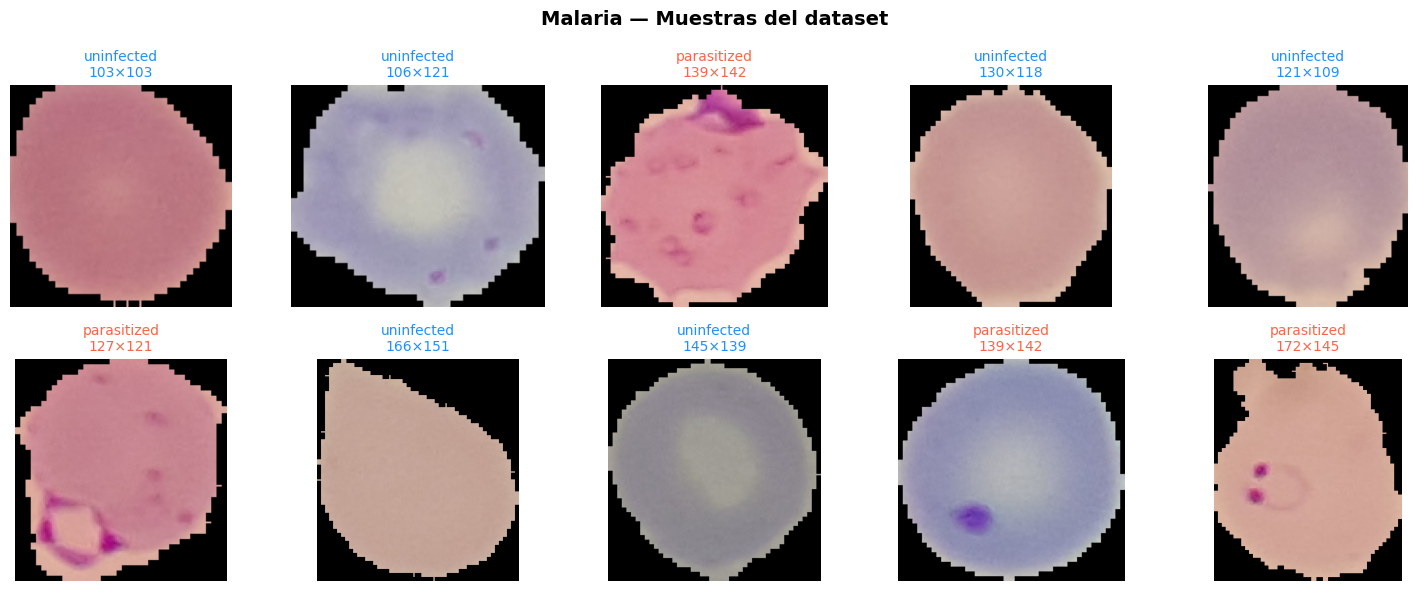

In [ ]:
# Muestras
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, (img, label) in enumerate(train_raw.take(10)):
    ax = axes[i // 5, i % 5]
    ax.imshow(img.numpy())
    ax.set_title(f"{CLASS_NAMES_1[label.numpy()]}\n{img.shape[0]}×{img.shape[1]}", fontsize=10,
                 color='tomato' if CLASS_NAMES_1[label.numpy()] == 'parasitized' else 'dodgerblue')
    ax.axis('off')
plt.suptitle('Malaria — Muestras del dataset', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

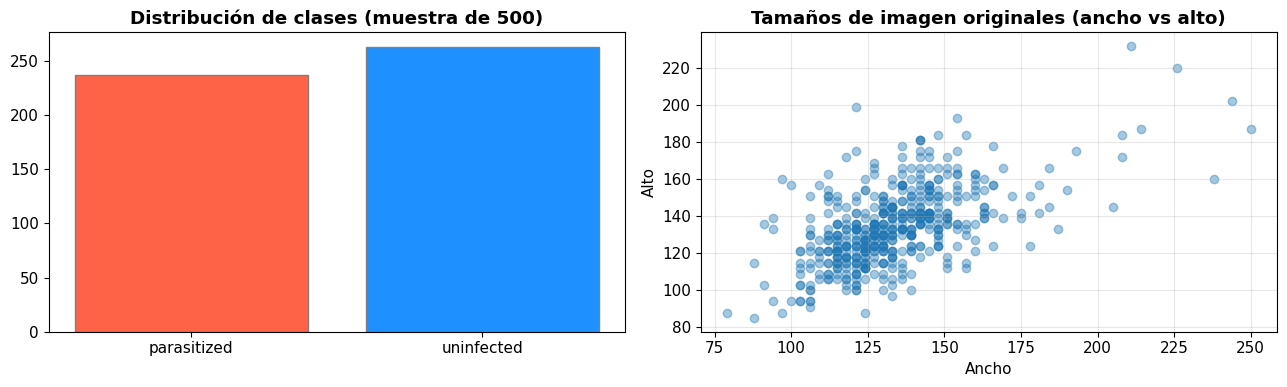

 Alto: 85–232 px (media 134) | Ancho: 79–250 px (media 133)
 Las imágenes tienen tamaños distintos y pequeños: habrá que redimensionarlas a 224×224.


In [ ]:
# EDA: distribución de clases y tamaños de imagen (muestra de 500)
labels_1 = [int(l) for _, l in train_raw.take(500)]
sizes = [tuple(img.shape[:2]) for img, _ in train_raw.take(500)]
hs = np.array([s[0] for s in sizes]); ws = np.array([s[1] for s in sizes])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
u, c = np.unique(labels_1, return_counts=True)
axes[0].bar([CLASS_NAMES_1[i] for i in u], c, color=['tomato', 'dodgerblue'], edgecolor='gray')
axes[0].set_title('Distribución de clases (muestra de 500)', fontweight='bold')
axes[1].scatter(ws, hs, alpha=0.4)
axes[1].set_title('Tamaños de imagen originales (ancho vs alto)', fontweight='bold')
axes[1].set_xlabel('Ancho'); axes[1].set_ylabel('Alto'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f" Alto: {hs.min()}–{hs.max()} px (media {hs.mean():.0f}) | Ancho: {ws.min()}–{ws.max()} px (media {ws.mean():.0f})")
print(" Las imágenes tienen tamaños distintos y pequeños: habrá que redimensionarlas a 224×224.")

### 1.2. Preprocesamiento
MobileNetV2 espera **224×224** y píxeles en **[-1, 1]** (`mobilenet_v2.preprocess_input`).

In [ ]:
IMG_SIZE_1 = (224, 224)

def preprocess_example1(image, label):
    image = tf.image.resize(image, IMG_SIZE_1)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES_1)
    return image, label

train_ds_1 = (train_raw.map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
              .shuffle(1000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds_1 = (val_raw.map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

xb, yb = next(iter(train_ds_1))
print(f"Batch: {xb.shape}, etiquetas: {yb.shape}, rango [{xb.numpy().min():.2f}, {xb.numpy().max():.2f}]")

Batch: (32, 224, 224, 3), etiquetas: (32, 2), rango [-1.00, 0.83]


### 1.3. Modelo con Feature Extraction
1. Cargar MobileNetV2 **sin** clasificador (`include_top=False`)
2. **Congelar** el backbone (`trainable = False`)
3. Agregar un clasificador nuevo

In [ ]:
base_model_1 = tf.keras.applications.MobileNetV2(
    weights='imagenet', include_top=False, input_shape=(*IMG_SIZE_1, 3))
base_model_1.trainable = False

print(f"Backbone: MobileNetV2 | Capas: {len(base_model_1.layers)} | "
      f"Params: {base_model_1.count_params():,} | Output: {base_model_1.output_shape}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Backbone: MobileNetV2 | Capas: 154 | Params: 2,257,984 | Output: (None, 7, 7, 1280)


In [ ]:
model_1 = models.Sequential([
    base_model_1,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES_1, activation='softmax')
], name='malaria_mobilenetv2_FE')
model_1.summary()

total = model_1.count_params()
trainable = sum(int(np.prod(w.shape)) for w in model_1.trainable_weights)
print(f"\n Total: {total:,} | Entrenables: {trainable:,} ({trainable/total*100:.2f}%) | Congelados: {total-trainable:,}")

Model: "malaria_mobilenetv2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


 Total: 2,260,546 | Entrenables: 2,562 (0.11%) | Congelados: 2,257,984


### 1.4. Entrenar y evaluar

In [ ]:
model_1.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                loss='categorical_crossentropy', metrics=['accuracy'])

history_1 = model_1.fit(
    train_ds_1, validation_data=val_ds_1, epochs=EPOCHS_1,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)]
)
print(f"\n Mejor val_accuracy: {max(history_1.history['val_accuracy']):.4f}")

Epoch 1/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 69s 72ms/step - accuracy: 0.8939 - loss: 0.2594 - val_accuracy: 0.9282 - val_loss: 0.1860
Epoch 2/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 38s 53ms/step - accuracy: 0.9274 - loss: 0.1953 - val_accuracy: 0.9432 - val_loss: 0.1630
Epoch 3/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 35s 50ms/step - accuracy: 0.9322 - loss: 0.1855 - val_accuracy: 0.9443 - val_loss: 0.1582
Epoch 4/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 37s 50ms/step - accuracy: 0.9355 - loss: 0.1825 - val_accuracy: 0.9407 - val_loss: 0.1640
Epoch 5/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 37s 52ms/step - accuracy: 0.9341 - loss: 0.1826 - val_accuracy: 0.9472 - val_loss: 0.1558
Epoch 6/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 36s 51ms/step - accuracy: 0.9360 - loss: 0.1806 - val_accuracy: 0.9438 - val_loss: 0.1577
Epoch 7/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 40s 56ms/step - accuracy: 0.9366 - loss: 0.1777 - val_accuracy: 0.9423 - val_loss: 0.1577
Epoch 8/8
689/689 ━━━━━━━━━━━━━━━━━━━━ 39s 56ms/step - accuracy: 0.9356 - loss: 0.1797 - val_accu

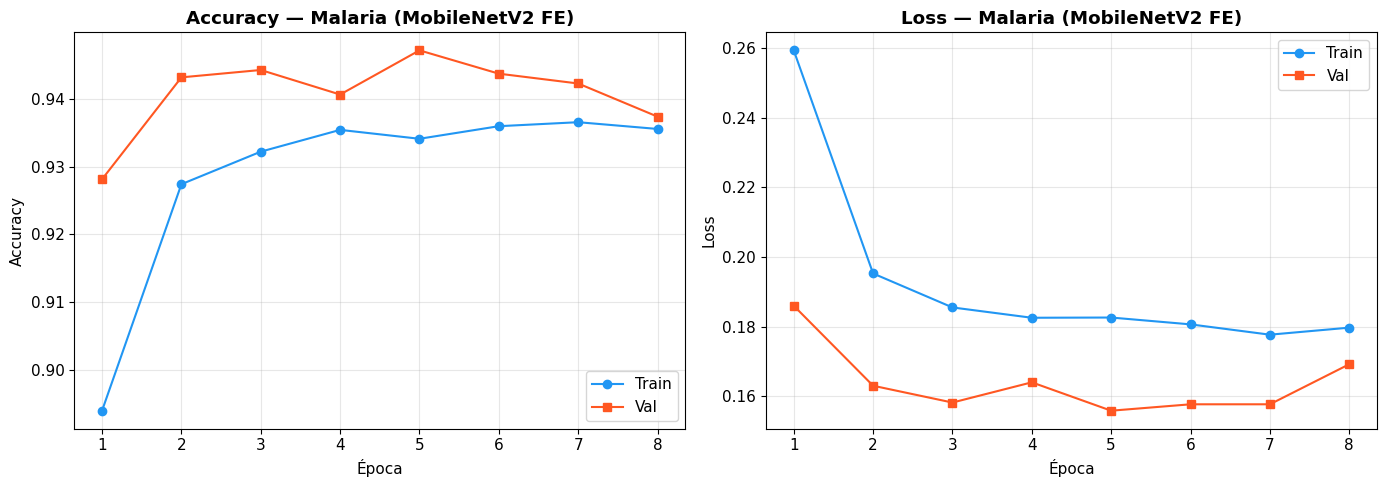

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep = range(1, len(history_1.history['accuracy']) + 1)
for ax, m, t in [(axes[0], 'accuracy', 'Accuracy'), (axes[1], 'loss', 'Loss')]:
    ax.plot(ep, history_1.history[m], 'o-', label='Train', color='#2196F3')
    ax.plot(ep, history_1.history['val_' + m], 's-', label='Val', color='#FF5722')
    ax.set_title(f'{t} — Malaria (MobileNetV2 FE)', fontweight='bold')
    ax.set_xlabel('Época'); ax.set_ylabel(t); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

              precision    recall  f1-score   support

 parasitized     0.9567    0.9378    0.9471      2780
  uninfected     0.9379    0.9568    0.9473      2732

    accuracy                         0.9472      5512
   macro avg     0.9473    0.9473    0.9472      5512
weighted avg     0.9474    0.9472    0.9472      5512



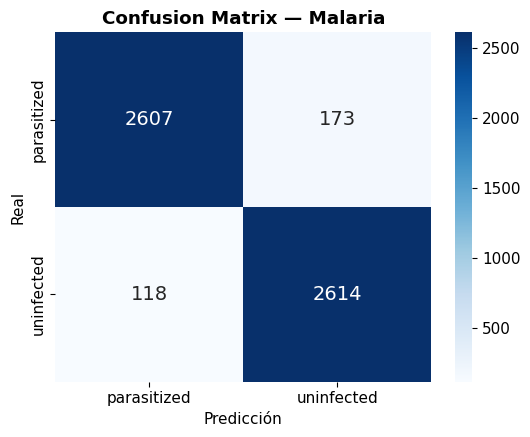

In [ ]:
# Métricas detalladas (clave en un problema médico: ¿cuántas células infectadas se nos escapan?)
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true_1, y_pred_1 = [], []
for images, lbls in val_ds_1:
    p = model_1.predict(images, verbose=0)
    y_pred_1.extend(np.argmax(p, axis=1)); y_true_1.extend(np.argmax(lbls.numpy(), axis=1))
y_true_1, y_pred_1 = np.array(y_true_1), np.array(y_pred_1)

print(classification_report(y_true_1, y_pred_1, target_names=CLASS_NAMES_1, digits=4))
cm1 = confusion_matrix(y_true_1, y_pred_1)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES_1,
            yticklabels=CLASS_NAMES_1, ax=ax, annot_kws={'size': 14})
ax.set_xlabel('Predicción'); ax.set_ylabel('Real'); ax.set_title('Confusion Matrix — Malaria', fontweight='bold')
plt.tight_layout(); plt.show()

### 1.5. Predicciones visuales

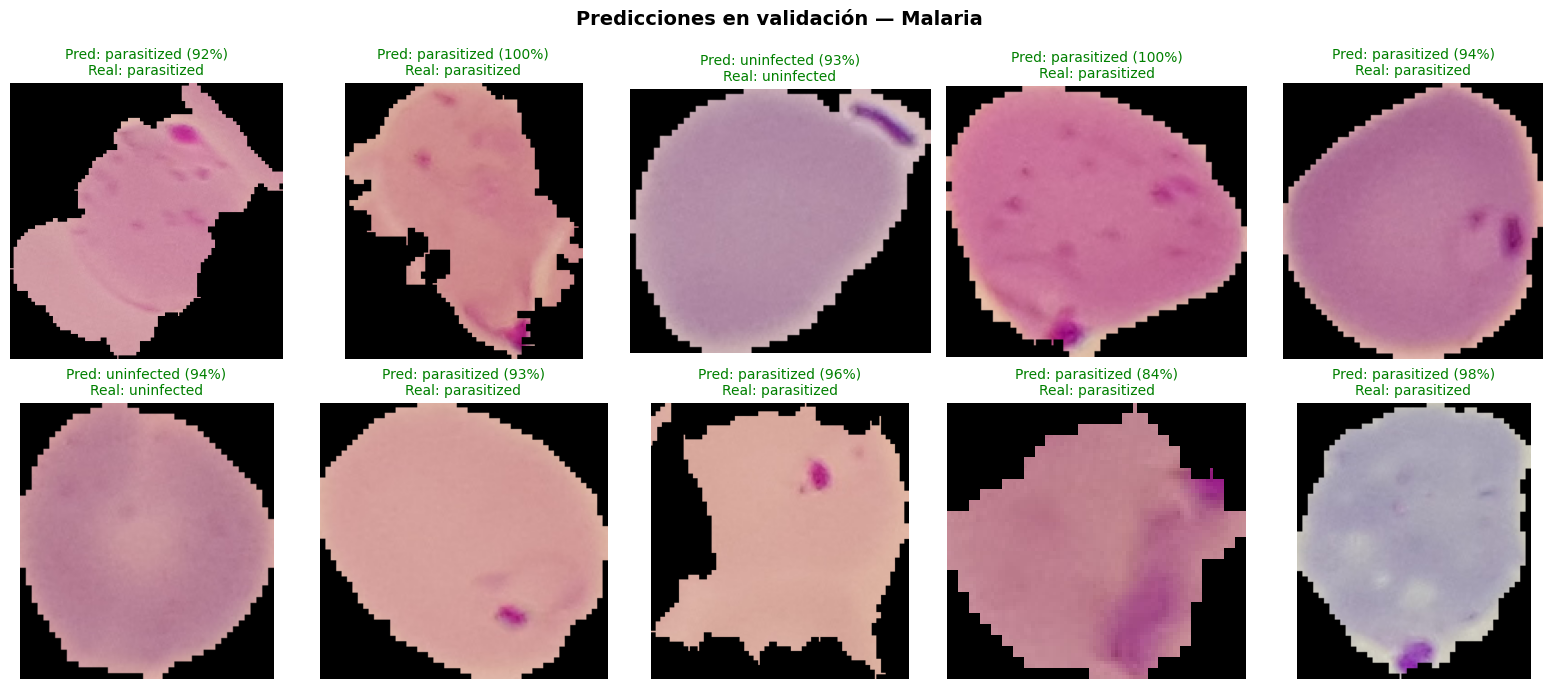

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for i, (img, label) in enumerate(val_raw.take(10)):
    ax = axes[i // 5, i % 5]
    x = tf.image.resize(img, IMG_SIZE_1)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(tf.expand_dims(x, 0))
    pred = model_1.predict(x, verbose=0)
    pred_class = CLASS_NAMES_1[int(np.argmax(pred))]
    true_class = CLASS_NAMES_1[int(label.numpy())]
    ax.imshow(img.numpy())
    ax.set_title(f"Pred: {pred_class} ({pred.max():.0%})\nReal: {true_class}", fontsize=10,
                 color='green' if pred_class == true_class else 'red')
    ax.axis('off')
plt.suptitle('Predicciones en validación — Malaria', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### ✅  Ejemplo 1
| Métrica | Valor |
|---|---|
| **Modelo base** | MobileNetV2 (~2.26M params, congelado) |
| **Parámetros entrenados** | solo el clasificador (≈2.500) |
| **Val Accuracy** | _0.9472_ |
| **Recall de `parasitized`** | _0.9378_ |



---
# 🟡 Ejemplo 2 — Intermedio: CIFAR-10.2 con EfficientNetB0

**Objetivo:** Feature Extraction con 10 clases, EDA, Data Augmentation, confusion matrix, classification report y feature maps.

**Dataset:** [CIFAR-10.2](https://galilai-group.github.io/stable-datasets/datasets/cifar10_2/) — 10,000 imágenes de train (1,000 por clase) y 2,000 de test (200 por clase), RGB 32×32. Clases: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck.

**Nota:** no tiene split de validación; usamos el `test` (2,000) como validación.

### 2.1. Cargar dataset y EDA

In [ ]:
!pip install git+https://github.com/galilai-group/stable-datasets.git

  Cloning https://github.com/galilai-group/stable-datasets.git to /tmp/pip-req-build-cmxwr0lo
  Running command git clone --filter=blob:none --quiet https://github.com/galilai-group/stable-datasets.git /tmp/pip-req-build-cmxwr0lo
  Resolved https://github.com/galilai-group/stable-datasets.git to commit 999dc58fd8f1eb5dc5bae0f455ed4a2555b2b0fe
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 94.4 MB/s  0:00:00
  Created wheel for stable-datasets: filename=stable_datasets-0.0.0a1-py3-none-any.whl size=624143 sha256=64740bd8ff6b5a2de622e5d19e68878f9492056c330e48f761bfe88d82300101
  Stored in directory: /tmp/pip-ephem-wheel-cache-py5ts1nx/wheels/e3/7d/20/e0192ea6283b6bc9024e4c975f6375679ce6df5c693e49c016
Successfully built stable-datasets
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [stable-datasets]


In [ ]:
from stable_datasets.images import CIFAR10_2

def stable_to_numpy(ds):
    '''Convierte un dataset de stable_datasets (PIL + label) a arrays NumPy.'''
    imgs, labs = [], []
    for ex in ds:
        im = ex['image']
        im = im.convert('RGB') if hasattr(im, 'convert') else im
        imgs.append(np.asarray(im, dtype=np.uint8))
        labs.append(int(ex['label']))
    return np.stack(imgs), np.array(labs, dtype=np.int64)

train_c = CIFAR10_2(split="train")
test_c = CIFAR10_2(split="test")
CLASS_NAMES_2 = list(train_c.info.features["label"].names)
NUM_CLASSES_2 = len(CLASS_NAMES_2)

x_train_2, y_train_2 = stable_to_numpy(train_c)
x_val_2, y_val_2 = stable_to_numpy(test_c)
print(f" Clases ({NUM_CLASSES_2}): {CLASS_NAMES_2}")
print(f" Train: {x_train_2.shape} | Val(test): {x_val_2.shape} | dtype={x_train_2.dtype}")

Output()

2026-11-06 00:10:24.899 | INFO     | stable_datasets.utils:download:691 - Downloading: https://raw.githubusercontent.com/modestyachts/cifar-10.2/master/cifar102_test.npz
2026-11-06 00:10:24.899 | INFO     | stable_datasets.utils:download:691 - Downloading: https://raw.githubusercontent.com/modestyachts/cifar-10.2/master/cifar102_train.npz
2026-11-06 00:10:25.323 | INFO     | stable_datasets.utils:download:711 - Total size: 6393664 bytes
2026-11-06 00:10:25.654 | INFO     | stable_datasets.utils:download:769 - Download finished: /root/.stable-datasets/downloads/cifar102_test.36b3a672c4.npz
2026-11-06 00:10:25.808 | INFO     | stable_datasets.utils:download:711 - Total size: 31961664 bytes
2026-11-06 00:10:27.473 | INFO     | stable_datasets.utils:download:769 - Download finished: /root/.stable-datasets/downloads/cifar102_train.3552eaca39.npz


2026-11-06 00:10:34.613 | INFO     | stable_datasets.cache:write_sharded_arrow_cache:283 - Cached 10000 examples in 1 shard(s) to /root/.stable-datasets/processed/cifar10_2_default_train_c320fc54a3731d94
2026-11-06 00:10:35.598 | INFO     | stable_datasets.cache:write_sharded_arrow_cache:283 - Cached 2000 examples in 1 shard(s) to /root/.stable-datasets/processed/cifar10_2_default_test_9866edb176fd9fd5


 Clases (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
 Train: (10000, 32, 32, 3) | Val(test): (2000, 32, 32, 3) | dtype=uint8


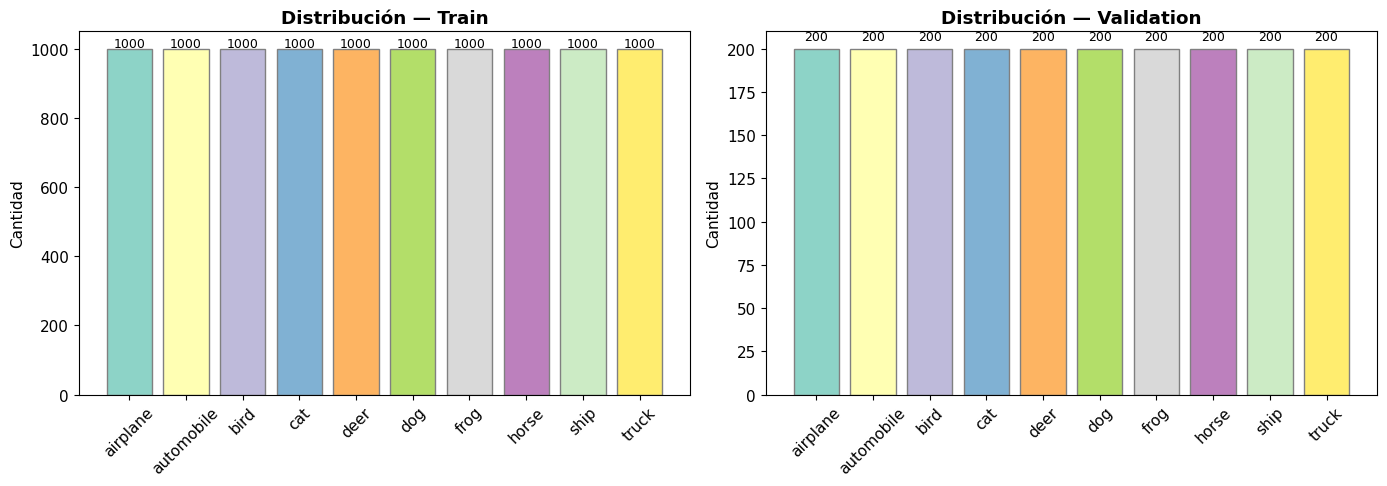

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, labs, t in [(axes[0], y_train_2, 'Train'), (axes[1], y_val_2, 'Validation')]:
    u, c = np.unique(labs, return_counts=True)
    bars = ax.bar([CLASS_NAMES_2[i] for i in u], c, color=plt.cm.Set3(np.linspace(0, 1, NUM_CLASSES_2)), edgecolor='gray')
    ax.set_title(f'Distribución — {t}', fontweight='bold'); ax.set_ylabel('Cantidad')
    ax.tick_params(axis='x', rotation=45)
    for b, v in zip(bars, c):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 5, str(v), ha='center', fontsize=9)
plt.tight_layout(); plt.show()

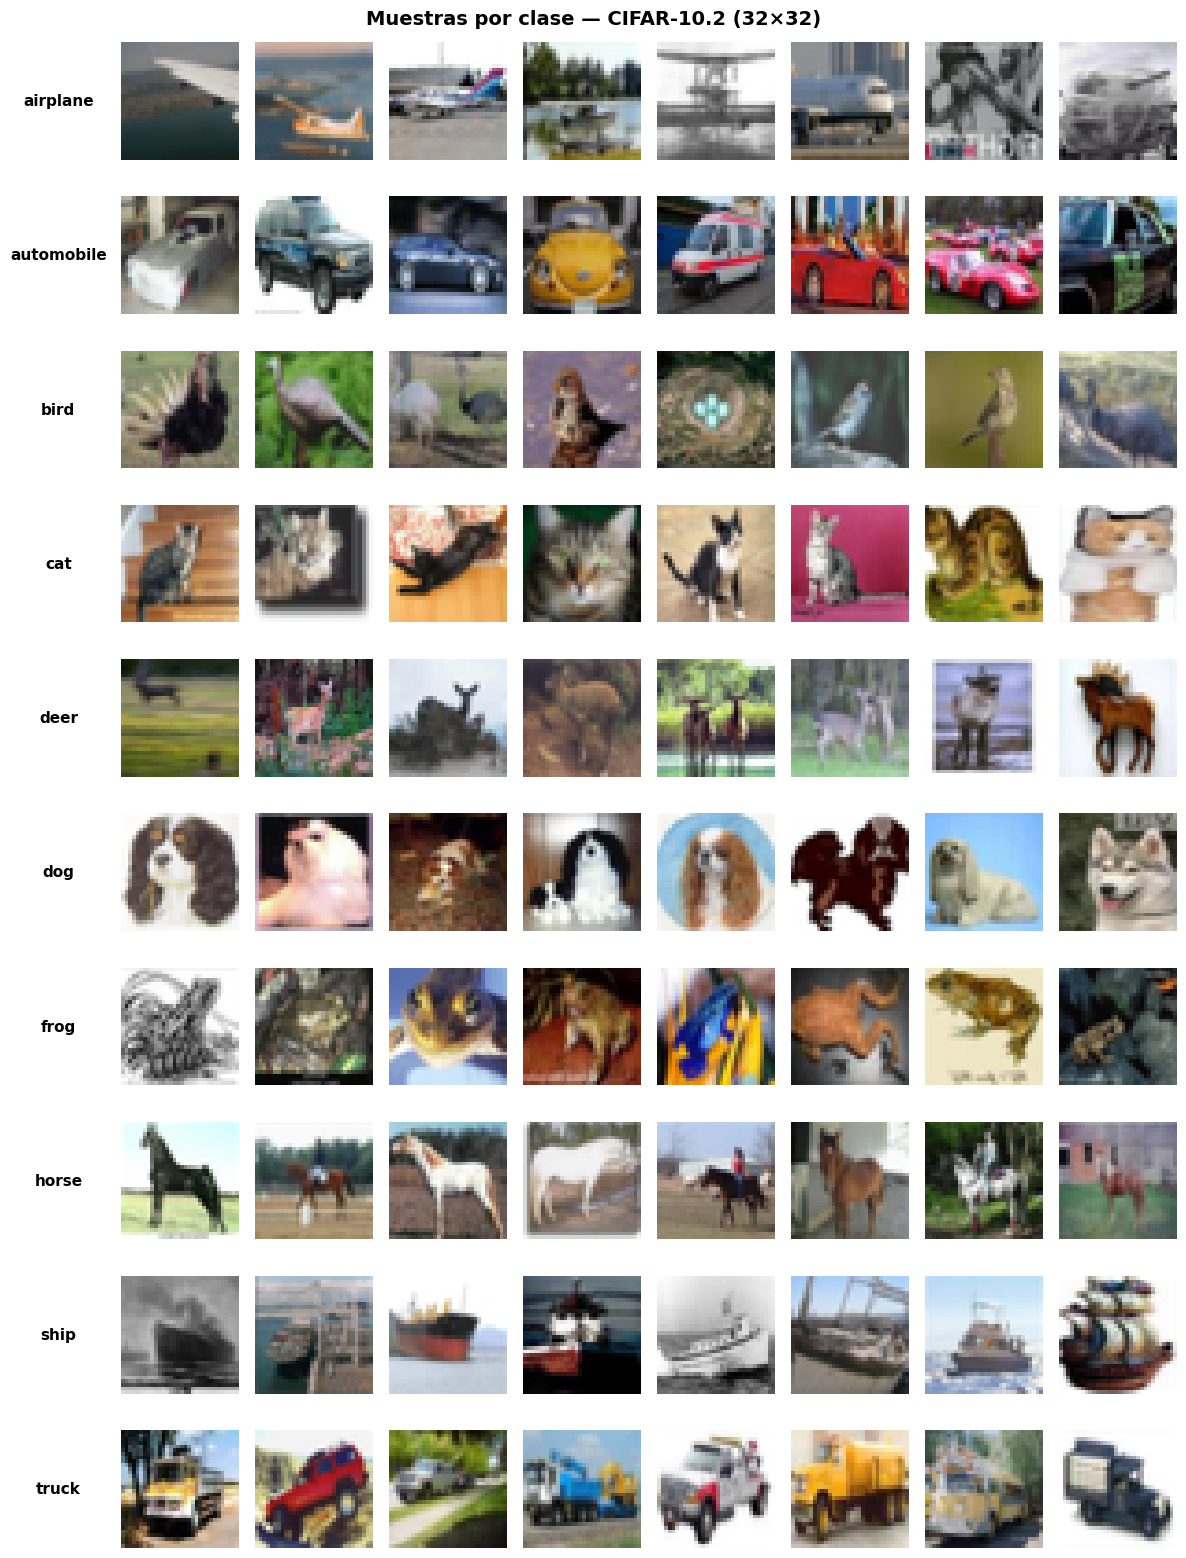

In [ ]:
# Muestras por clase
fig, axes = plt.subplots(NUM_CLASSES_2, 8, figsize=(12, 1.6 * NUM_CLASSES_2))
for k in range(NUM_CLASSES_2):
    idx = np.where(y_train_2 == k)[0][:8]
    for j, i in enumerate(idx):
        axes[k, j].imshow(x_train_2[i]); axes[k, j].axis('off')
    axes[k, 0].set_ylabel(CLASS_NAMES_2[k], rotation=0, labelpad=45, va='center', fontweight='bold')
    axes[k, 0].axis('on'); axes[k, 0].set_xticks([]); axes[k, 0].set_yticks([])
    for s in axes[k, 0].spines.values(): s.set_visible(False)
plt.suptitle('Muestras por clase — CIFAR-10.2 (32×32)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### 2.2. Preprocesamiento + Data Augmentation
Las imágenes son de **32×32**; las escalamos a **224×224** para el backbone. El *augmentation* se hace **dentro del modelo** (solo está activo en entrenamiento). Aquí sí podemos usar `RandomFlip` horizontal: un caballo volteado sigue siendo un caballo.

In [ ]:
IMG_SIZE_2 = (224, 224)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name='augmentation')

def make_ds(x, y, num_classes, training=False, preprocess_fn=None, batch=BATCH_SIZE):
    '''uint8 32×32 -> float32 224×224 (+ preprocess_input opcional) en batches.'''
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED)
    def _f(img, lbl):
        img = tf.image.resize(tf.cast(img, tf.float32), IMG_SIZE_2)
        if preprocess_fn is not None:
            img = preprocess_fn(img)
        return img, tf.one_hot(lbl, num_classes)
    return ds.map(_f, num_parallel_calls=tf.data.AUTOTUNE).batch(batch).prefetch(tf.data.AUTOTUNE)

# EfficientNet incluye su normalización dentro del modelo -> entra en [0, 255]
train_ds_2 = make_ds(x_train_2, y_train_2, NUM_CLASSES_2, training=True)
val_ds_2 = make_ds(x_val_2, y_val_2, NUM_CLASSES_2)
print("Datasets listos")

Datasets listos


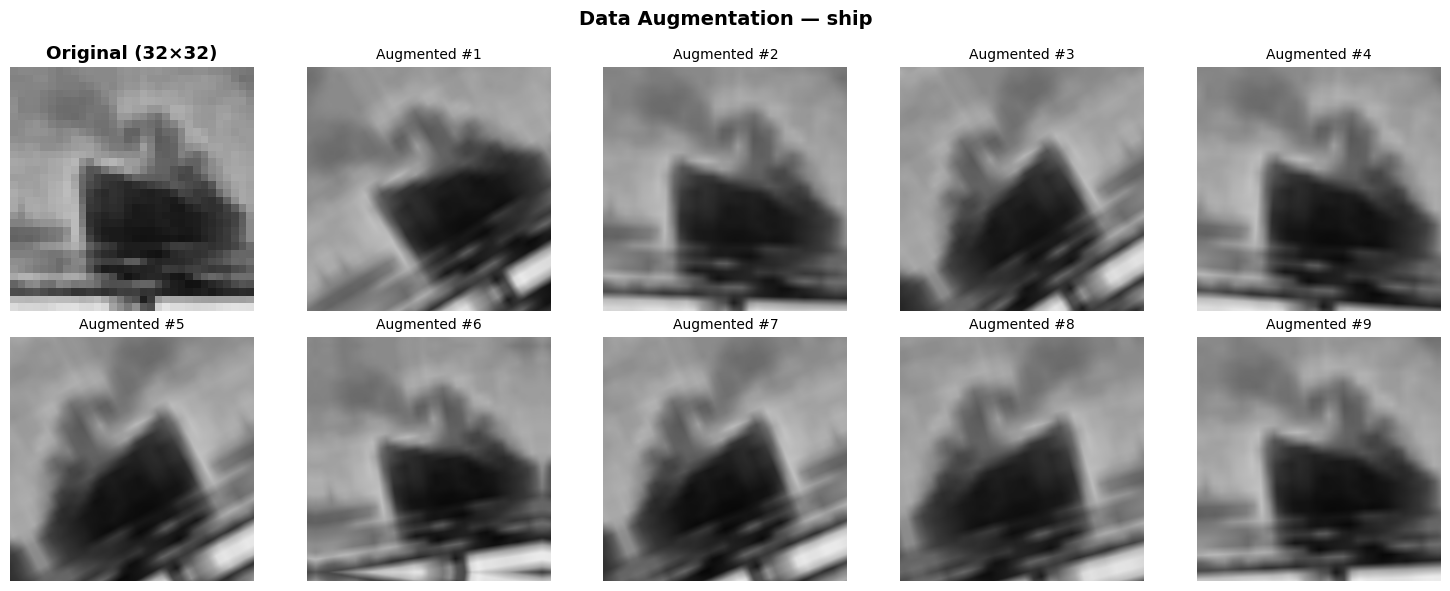

In [ ]:
# Visualizar augmentation
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
sample = tf.image.resize(tf.cast(x_train_2[0], tf.float32), IMG_SIZE_2)
axes[0, 0].imshow(x_train_2[0]); axes[0, 0].set_title('Original (32×32)', fontweight='bold'); axes[0, 0].axis('off')
for i in range(1, 10):
    ax = axes[i // 5, i % 5]
    aug = data_augmentation(tf.expand_dims(sample, 0), training=True)
    ax.imshow(aug[0].numpy().astype('uint8')); ax.set_title(f'Augmented #{i}', fontsize=10); ax.axis('off')
plt.suptitle(f'Data Augmentation — {CLASS_NAMES_2[y_train_2[0]]}', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### 2.3. Modelo con EfficientNetB0

In [ ]:
base_model_2 = tf.keras.applications.EfficientNetB0(
    weights='imagenet', include_top=False, input_shape=(*IMG_SIZE_2, 3))
base_model_2.trainable = False

inputs_2 = layers.Input(shape=(*IMG_SIZE_2, 3))
x = data_augmentation(inputs_2)                 # solo activo en entrenamiento
x = base_model_2(x, training=False)             # BN en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs_2 = layers.Dense(NUM_CLASSES_2, activation='softmax')(x)
model_2 = models.Model(inputs_2, outputs_2, name='cifar10_2_efficientnetb0_FE')

total = model_2.count_params()
trainable = sum(int(np.prod(w.shape)) for w in model_2.trainable_weights)
print(f"Total: {total:,} | Entrenables: {trainable:,} ({trainable/total*100:.2f}%) | Congelados: {total-trainable:,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total: 4,219,949 | Entrenables: 167,818 (3.98%) | Congelados: 4,052,131


### 2.4. Entrenar con callbacks

In [ ]:
model_2.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                loss='categorical_crossentropy', metrics=['accuracy'])
history_2 = model_2.fit(
    train_ds_2, validation_data=val_ds_2, epochs=EPOCHS_2,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ])
print(f"\n Mejor val_accuracy: {max(history_2.history['val_accuracy']):.4f}")

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 56s 107ms/step - accuracy: 0.5577 - loss: 1.3665 - val_accuracy: 0.7660 - val_loss: 0.7019 - learning_rate: 0.0010
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 95ms/step - accuracy: 0.6408 - loss: 1.0428 - val_accuracy: 0.7750 - val_loss: 0.6643 - learning_rate: 0.0010
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 94ms/step - accuracy: 0.6763 - loss: 0.9315 - val_accuracy: 0.7935 - val_loss: 0.6320 - learning_rate: 0.0010
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 95ms/step - accuracy: 0.6839 - loss: 0.8845 - val_accuracy: 0.7980 - val_loss: 0.6097 - learning_rate: 0.0010
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 93ms/step - accuracy: 0.6973 - loss: 0.8580 - val_accuracy: 0.7950 - val_loss: 0.6108 - learning_rate: 0.0010
Epoch 6/15
312/313 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.7067 - loss: 0.8257
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 95ms/step - accuracy: 0.7043 - lo

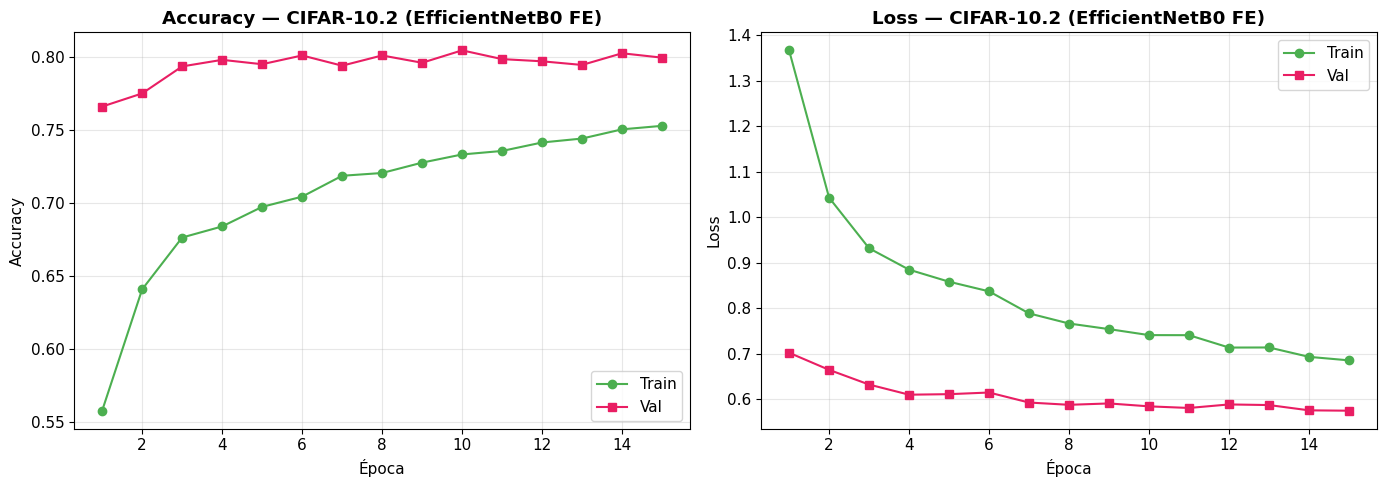

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep = range(1, len(history_2.history['accuracy']) + 1)
for ax, m, t in [(axes[0], 'accuracy', 'Accuracy'), (axes[1], 'loss', 'Loss')]:
    ax.plot(ep, history_2.history[m], 'o-', label='Train', color='#4CAF50')
    ax.plot(ep, history_2.history['val_' + m], 's-', label='Val', color='#E91E63')
    ax.set_title(f'{t} — CIFAR-10.2 (EfficientNetB0 FE)', fontweight='bold')
    ax.set_xlabel('Época'); ax.set_ylabel(t); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 2.5. Evaluación detallada: Confusion Matrix + Classification Report

In [ ]:
y_true, y_pred = [], []
for images, lbls in val_ds_2:
    p = model_2.predict(images, verbose=0)
    y_pred.extend(np.argmax(p, axis=1)); y_true.extend(np.argmax(lbls.numpy(), axis=1))
y_true, y_pred = np.array(y_true), np.array(y_pred)

print("Classification Report — CIFAR-10.2 (EfficientNetB0 FE)")
print("=" * 65)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES_2, digits=4))

Classification Report — CIFAR-10.2 (EfficientNetB0 FE)
              precision    recall  f1-score   support

    airplane     0.7650    0.7000    0.7311       200
  automobile     0.7772    0.7850    0.7811       200
        bird     0.8250    0.8250    0.8250       200
         cat     0.7753    0.6900    0.7302       200
        deer     0.8095    0.7650    0.7866       200
         dog     0.8182    0.8550    0.8362       200
        frog     0.8066    0.8550    0.8301       200
       horse     0.8398    0.8650    0.8522       200
        ship     0.8077    0.8400    0.8235       200
       truck     0.7653    0.8150    0.7893       200

    accuracy                         0.7995      2000
   macro avg     0.7990    0.7995    0.7985      2000
weighted avg     0.7990    0.7995    0.7985      2000



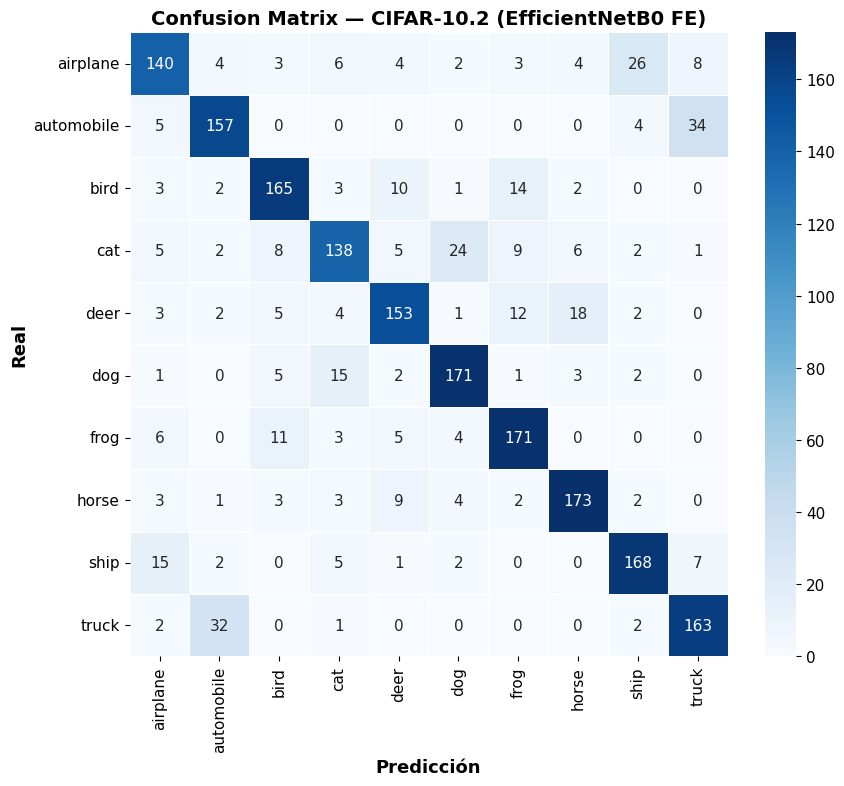


 Principales confusiones (real → predicho):
   automobile → truck     : 34 veces
        truck → automobile: 32 veces
     airplane → ship      : 26 veces
          cat → dog       : 24 veces
         deer → horse     : 18 veces
         ship → airplane  : 15 veces


In [ ]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES_2, yticklabels=CLASS_NAMES_2,
            ax=ax, linewidths=0.5, linecolor='white')
ax.set_xlabel('Predicción', fontsize=13, fontweight='bold'); ax.set_ylabel('Real', fontsize=13, fontweight='bold')
ax.set_title('Confusion Matrix — CIFAR-10.2 (EfficientNetB0 FE)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print("\n Principales confusiones (real → predicho):")
pairs = [(cm[i, j], i, j) for i in range(NUM_CLASSES_2) for j in range(NUM_CLASSES_2) if i != j and cm[i, j] > 0]
for n, i, j in sorted(pairs, reverse=True)[:6]:
    print(f"   {CLASS_NAMES_2[i]:>10} → {CLASS_NAMES_2[j]:<10}: {n} veces")

### 2.6. Visualización de Feature Maps

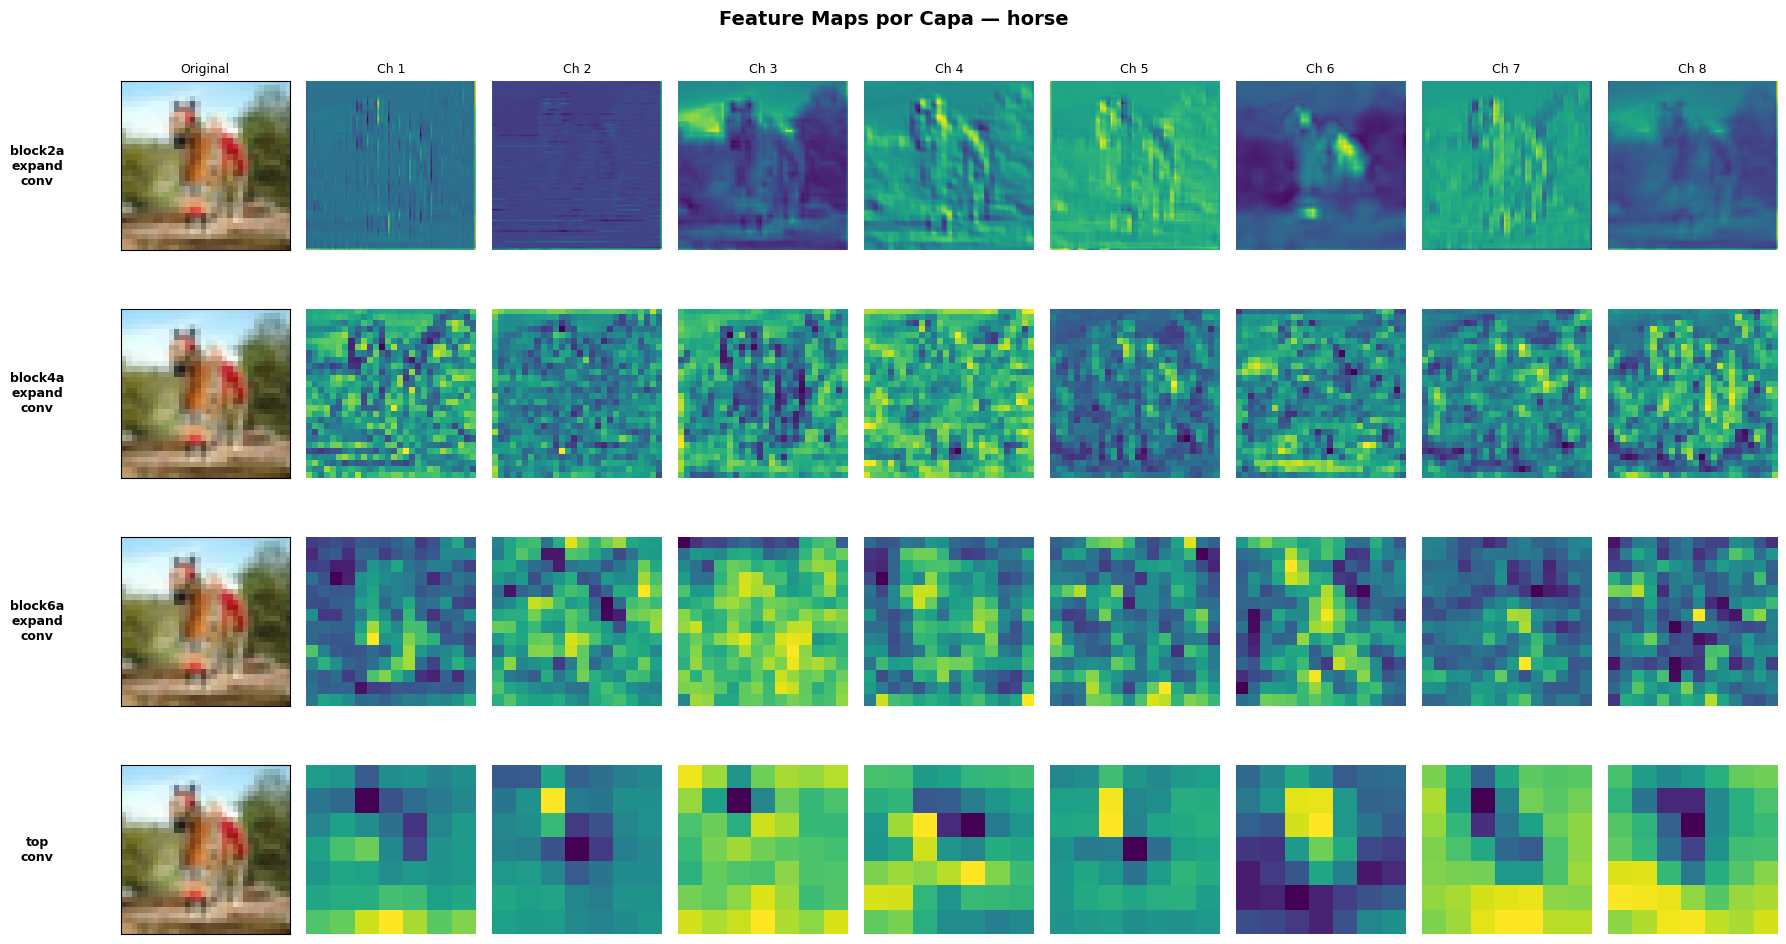

In [ ]:
layer_names = ['block2a_expand_conv', 'block4a_expand_conv', 'block6a_expand_conv', 'top_conv']
feature_models = [models.Model(inputs=base_model_2.input, outputs=base_model_2.get_layer(n).output)
                  for n in layer_names]

idx = int(np.where(y_val_2 == CLASS_NAMES_2.index('horse'))[0][0]) if 'horse' in CLASS_NAMES_2 else 0
img32 = x_val_2[idx]
sample_proc = tf.image.resize(tf.cast(img32, tf.float32), IMG_SIZE_2)
sample_proc = tf.expand_dims(sample_proc, 0)

fig, axes = plt.subplots(len(layer_names), 9, figsize=(18, 2.5 * len(layer_names)))
for row, (fm, name) in enumerate(zip(feature_models, layer_names)):
    feats = fm.predict(sample_proc, verbose=0)
    axes[row, 0].imshow(img32)
    axes[row, 0].set_title('Original' if row == 0 else '', fontsize=9)
    axes[row, 0].set_ylabel(name.replace('_', '\n'), fontsize=9, fontweight='bold', rotation=0, labelpad=60, va='center')
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    for col in range(1, 9):
        ax = axes[row, col]
        ax.imshow(feats[0, :, :, col - 1], cmap='viridis'); ax.axis('off')
        if row == 0: ax.set_title(f'Ch {col}', fontsize=9)
plt.suptitle(f'Feature Maps por Capa — {CLASS_NAMES_2[y_val_2[idx]]}', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

> Las capas tempranas detectan bordes y texturas; las intermedias, partes y formas; las profundas, abstracciones de alto nivel. Con imágenes de 32×32 reescaladas, los mapas se ven más borrosos que con fotos nítidas: es una limitación del dataset.

### ✅ Conclusión Ejemplo 2

| Métrica | Valor |
|---|---|
| **Modelo base** | EfficientNetB0 (congelado 4M) |
| **Val Accuracy** | _0.8045_ |
| **Clases más confundidas** | _ mayormente cat-dog y automobile-truck_ |
| **Augmentation** | Flip + Rotation + Zoom + Contrast |

---
# 🔴 Ejemplo 3 — Avanzado: Comparación de Backbones + t-SNE

**Objetivo:** comparar 4 backbones bajo las mismas condiciones y visualizar con t-SNE cómo los features transferidos separan las clases.

**Dataset:** CIFAR-10.2.

**Backbones:** MobileNetV2 · ResNet50 · EfficientNetB0 · DenseNet121

> ⚠️ Cada backbone usa **su propio `preprocess_input`**. Aquí lo aplicamos en el dataset de cada uno para que la comparación sea justa.

### 3.1. Función de benchmark

In [ ]:
def benchmark_backbone(backbone_fn, preprocess_fn, name, num_classes, epochs=10, img_size=(224, 224)):
    '''Entrena Feature Extraction con un backbone y retorna métricas.'''
    train_ds = make_ds(x_train_2, y_train_2, num_classes, training=True, preprocess_fn=preprocess_fn)
    val_ds = make_ds(x_val_2, y_val_2, num_classes, preprocess_fn=preprocess_fn)

    base = backbone_fn(weights='imagenet', include_top=False, input_shape=(*img_size, 3))
    base.trainable = False

    inp = layers.Input(shape=(*img_size, 3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    model = models.Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])

    trainable_count = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    t0 = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0,
                        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)])
    train_time = time.time() - t0
    best = max(history.history['val_accuracy'])
    return {
        'Backbone': name,
        'Params backbone': f"{base.count_params():,}",
        'Params entrenables': f"{trainable_count:,}",
        'Best Val Acc': f"{best:.4f}",
        'Mejor época': history.history['val_accuracy'].index(best) + 1,
        'Tiempo (s)': f"{train_time:.0f}",
        'model': model, 'history': history, 'base_model': base, 'val_ds': val_ds,
    }

### 3.2. Ejecutar el benchmark

In [ ]:
A = tf.keras.applications
backbones = [
    (A.MobileNetV2,    A.mobilenet_v2.preprocess_input, 'MobileNetV2'),
    (A.ResNet50,       A.resnet.preprocess_input,       'ResNet50'),
    (A.EfficientNetB0, A.efficientnet.preprocess_input, 'EfficientNetB0'),
    (A.DenseNet121,    A.densenet.preprocess_input,     'DenseNet121'),
]

results = []
for fn, prep, name in backbones:
    print(f"\n{'='*50}\n Entrenando: {name}\n{'='*50}")
    r = benchmark_backbone(fn, prep, name, NUM_CLASSES_2, epochs=EPOCHS_BENCH)
    results.append(r)
    print(f"  {name}: val_acc = {r['Best Val Acc']}, tiempo = {r['Tiempo (s)']}s")
print("\n Benchmark completado!")


 Entrenando: MobileNetV2
  MobileNetV2: val_acc = 0.7495, tiempo = 117s

 Entrenando: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
  ResNet50: val_acc = 0.7985, tiempo = 337s

 Entrenando: EfficientNetB0
  EfficientNetB0: val_acc = 0.8100, tiempo = 148s

 Entrenando: DenseNet121
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
  DenseNet121: val_acc = 0.7955, tiempo = 343s

 Benchmark completado!


In [ ]:
df_results = pd.DataFrame([{k: v for k, v in r.items() if k not in ('model', 'history', 'base_model', 'val_ds')} for r in results])
print(" TABLA COMPARATIVA DE BACKBONES"); print("=" * 80)
print(df_results.to_string(index=False))

 TABLA COMPARATIVA DE BACKBONES
      Backbone Params backbone Params entrenables Best Val Acc  Mejor época Tiempo (s)
   MobileNetV2       2,257,984            167,818       0.7495            4        117
      ResNet50      23,587,712            267,658       0.7985            4        337
EfficientNetB0       4,049,571            167,818       0.8100            4        148
   DenseNet121       7,037,504            134,538       0.7955            8        343


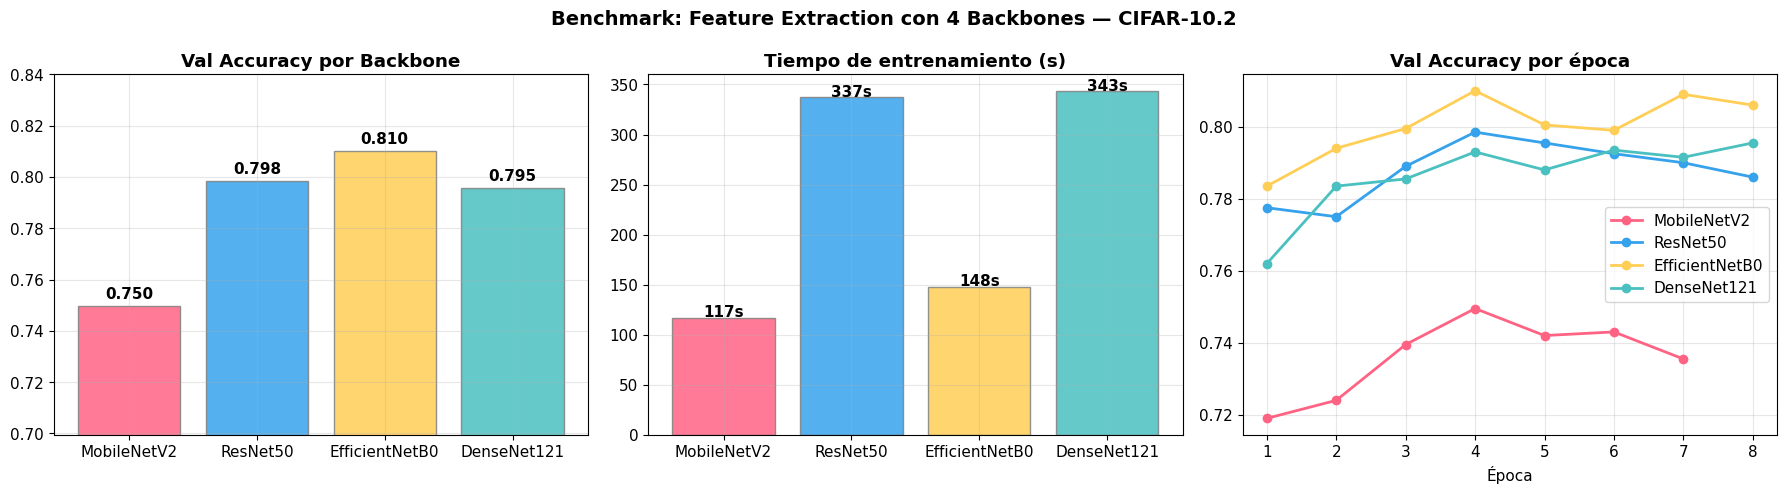

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#FF6384', '#36A2EB', '#FFCE56', '#4BC0C0']
names = [r['Backbone'] for r in results]
accs = [float(r['Best Val Acc']) for r in results]
times = [float(r['Tiempo (s)']) for r in results]

bars = axes[0].bar(names, accs, color=colors, edgecolor='gray', alpha=0.85)
axes[0].set_title('Val Accuracy por Backbone', fontweight='bold'); axes[0].set_ylim([min(accs) - 0.05, min(1, max(accs) + 0.03)])
for b, v in zip(bars, accs):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.003, f'{v:.3f}', ha='center', fontweight='bold')
bars2 = axes[1].bar(names, times, color=colors, edgecolor='gray', alpha=0.85)
axes[1].set_title('Tiempo de entrenamiento (s)', fontweight='bold')
for b, v in zip(bars2, times):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 1, f'{v:.0f}s', ha='center', fontweight='bold')
for r, c in zip(results, colors):
    h = r['history'].history['val_accuracy']
    axes[2].plot(range(1, len(h) + 1), h, 'o-', label=r['Backbone'], color=c, linewidth=2)
axes[2].set_title('Val Accuracy por época', fontweight='bold'); axes[2].set_xlabel('Época'); axes[2].legend()
for a in axes: a.grid(alpha=0.3)
plt.suptitle('Benchmark: Feature Extraction con 4 Backbones — CIFAR-10.2', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### 3.3. Visualización t-SNE de features transferidos
t-SNE proyecta features de alta dimensión a 2D. Si cada clase forma su propio cúmulo, el backbone separa bien las clases.

In [ ]:
from sklearn.manifold import TSNE

def extract_features(model, dataset, max_samples=TSNE_SAMPLES):
    '''Features de la capa justo antes del clasificador denso (salida del BatchNorm tras el GAP).'''
    fe = models.Model(inputs=model.input, outputs=model.layers[-5].output)
    feats, labs, n = [], [], 0
    for imgs, lbls in dataset:
        feats.append(fe.predict(imgs, verbose=0)); labs.append(np.argmax(lbls.numpy(), axis=1))
        n += imgs.shape[0]
        if n >= max_samples: break
    return np.concatenate(feats)[:max_samples], np.concatenate(labs)[:max_samples]

best_idx = int(np.argmax([float(r['Best Val Acc']) for r in results]))
best = results[best_idx]; best_name = best['Backbone']
print(f" Mejor backbone: {best_name}")
features, labels = extract_features(best['model'], best['val_ds'])
print(f" Features: {features.shape}")

 Mejor backbone: EfficientNetB0
 Features: (1000, 1280)


 Calculando t-SNE...


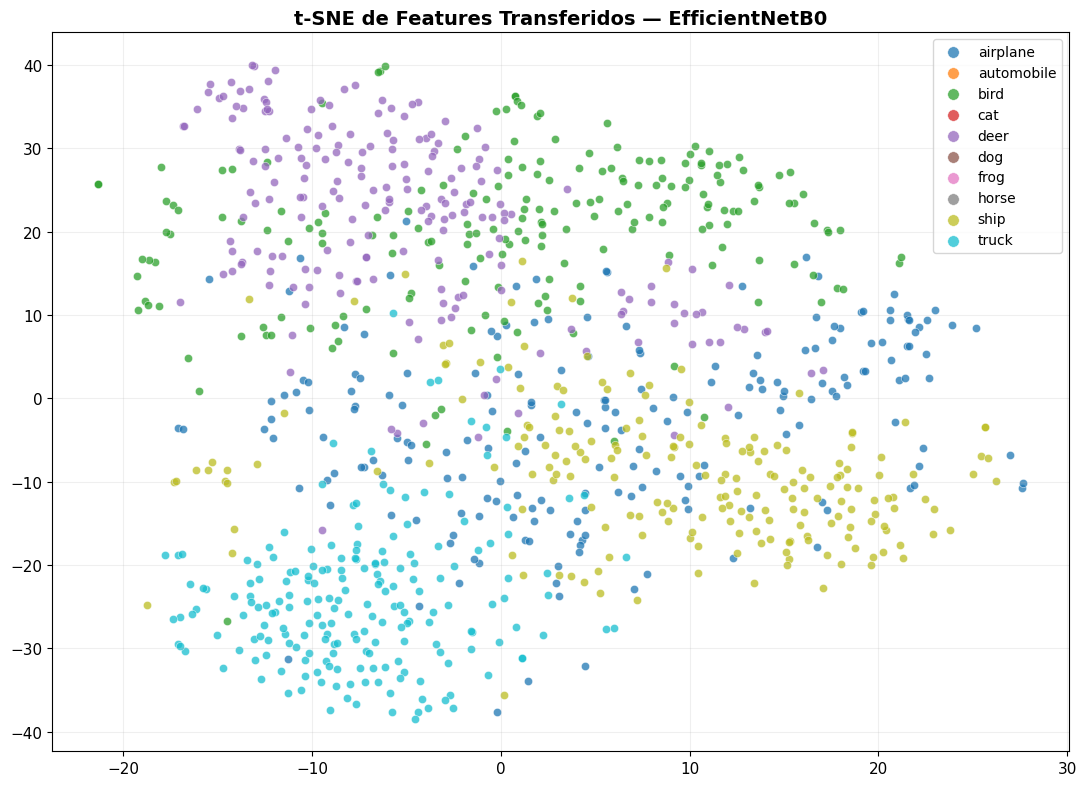

In [ ]:
print(" Calculando t-SNE...")
features_2d = TSNE(n_components=2, random_state=SEED, perplexity=30).fit_transform(features)
scatter_colors = plt.cm.tab10(np.linspace(0, 1, NUM_CLASSES_2))

fig, ax = plt.subplots(figsize=(11, 8))
for k in range(NUM_CLASSES_2):
    m = labels == k
    ax.scatter(features_2d[m, 0], features_2d[m, 1], c=[scatter_colors[k]], label=CLASS_NAMES_2[k],
               alpha=0.75, s=35, edgecolors='white', linewidths=0.4)
ax.set_title(f't-SNE de Features Transferidos — {best_name}', fontsize=14, fontweight='bold')
ax.legend(fontsize=10, markerscale=1.4, loc='best'); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

### 3.4. Features aleatorios vs. features transferidos (EfficientNetB0)

In [ ]:
# Misma arquitectura (EfficientNetB0), con pesos ALEATORIOS vs pesos de ImageNet
eff_res = next(r for r in results if r['Backbone'] == 'EfficientNetB0')
base_random = A.EfficientNetB0(weights=None, include_top=False, input_shape=(224, 224, 3))
gap = layers.GlobalAveragePooling2D()

def gap_features(base, dataset, max_samples=TSNE_SAMPLES):
    f, l, n = [], [], 0
    for imgs, lbls in dataset:
        f.append(gap(base.predict(imgs, verbose=0)).numpy()); l.append(np.argmax(lbls.numpy(), axis=1))
        n += imgs.shape[0]
        if n >= max_samples: break
    return np.concatenate(f)[:max_samples], np.concatenate(l)[:max_samples]

val_eff = eff_res['val_ds']
f_rand, l_rand = gap_features(base_random, val_eff)
f_imnet, l_imnet = gap_features(eff_res['base_model'], val_eff)
rand_2d = TSNE(n_components=2, random_state=SEED, perplexity=30).fit_transform(f_rand)
imnet_2d = TSNE(n_components=2, random_state=SEED, perplexity=30).fit_transform(f_imnet)

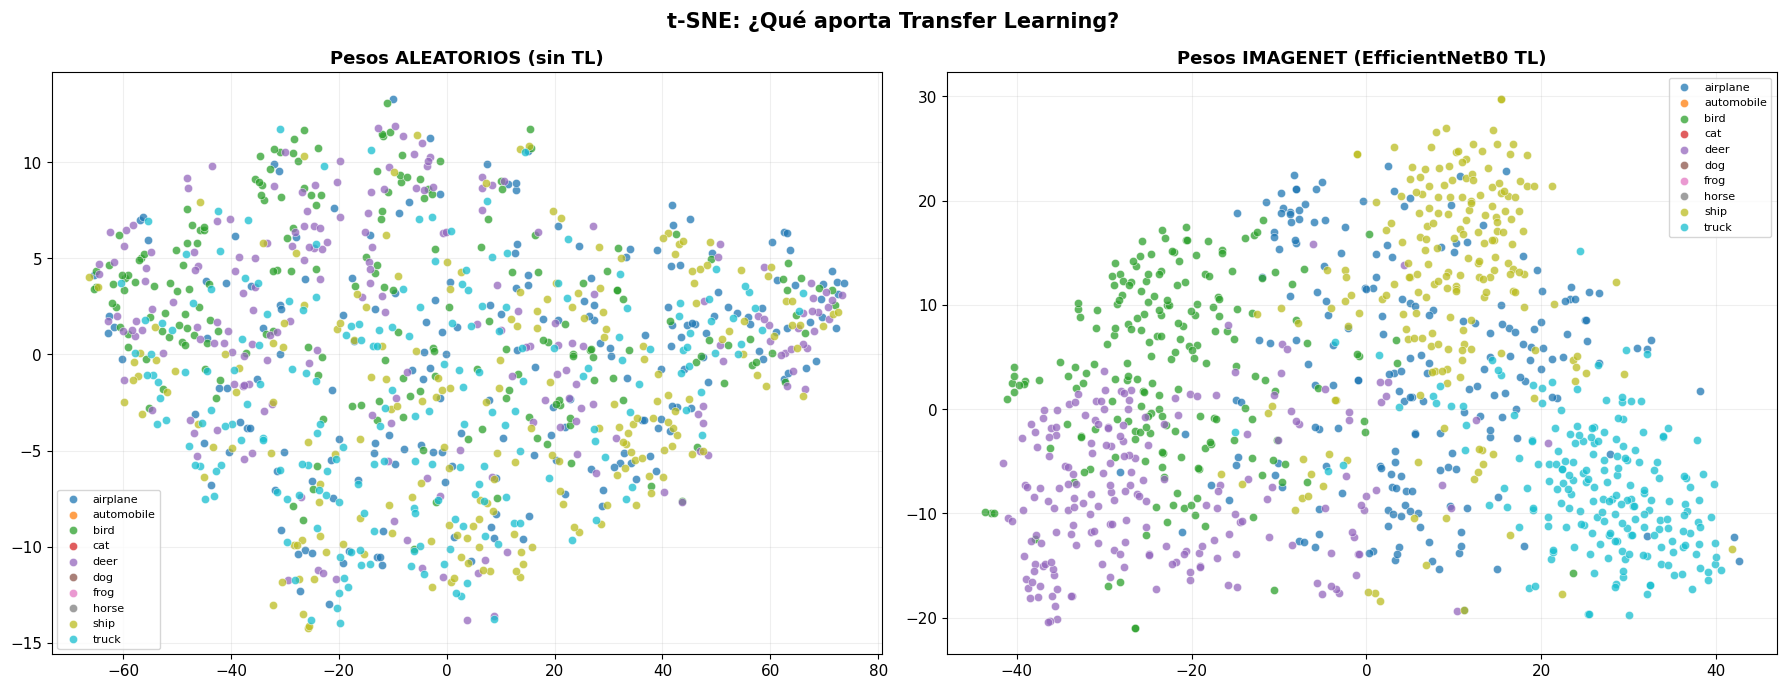

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, data, lab, t in [(axes[0], rand_2d, l_rand, 'Pesos ALEATORIOS (sin TL)'),
                         (axes[1], imnet_2d, l_imnet, 'Pesos IMAGENET (EfficientNetB0 TL)')]:
    for k in range(NUM_CLASSES_2):
        m = lab == k
        ax.scatter(data[m, 0], data[m, 1], c=[scatter_colors[k]], label=CLASS_NAMES_2[k],
                   alpha=0.75, s=35, edgecolors='white', linewidths=0.4)
    ax.set_title(t, fontsize=13, fontweight='bold'); ax.legend(fontsize=8); ax.grid(alpha=0.2)
plt.suptitle('t-SNE: ¿Qué aporta Transfer Learning?', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

### ✅ Conclusión Ejemplo 3
1. Mejor backbone: _EfficientNetB0_  con: _0.8100_.
2. ResNet50 y EfficientNetB0 son los que mejor valor accuracy llegaron a dar
3. t-SNE: los features con pesos de ImageNet deberían formar cúmulos más definidos (p. ej. vehículos separados de animales) que los pesos aleatorios.
4. Las imágenes originales son de solo 32×32; reescalarlas a 224×224 limita el máximo alcanzable con Feature Extraction. Esto motiva el **Fine-Tuning** (Sesión 09-B).

---
# 📋 Resumen de la Sesión 09-A

| Concepto | Descripción |
|---|---|
| **Transfer Learning** | Reutilizar conocimiento de ImageNet en otro problema |
| **Feature Extraction** | Congelar backbone + entrenar solo el clasificador nuevo |
| **`include_top=False`** | Quitar las capas Dense originales de 1000 clases |
| **`trainable = False`** | Congelar los pesos del backbone |
| **`preprocess_input`** | Cada modelo tiene su propia normalización |
| **`training=False`** | Las capas BN usan los estadísticos de ImageNet |
| **t-SNE** | Visualización 2D de features de alta dimensión |

**Datasets usados:** Malaria (células, 2 clases) y CIFAR-10.2 (objetos, 10 clases).

**Próximo paso:** Sesión 09-B — Fine-Tuning.